# Figura 2 · La distribución de los salarios en España, 2008-2024

Este cuaderno dibuja la Figura 2 del trabajo a partir de una tabla ya preparada en el cuaderno principal (`TP_08MBID_preparacion_datos.ipynb`, paso 1): `data/processed/salarios_ccaa.csv`. No crea ninguna tabla nueva.

**Qué muestra.** Para cada año, el salario bruto anual por trabajador en cinco puntos de la distribución (percentil 10, primer cuartil, mediana, tercer cuartil y percentil 90) y la media. Las franjas reparten a los asalariados en grupos, y en el centro de cada una se indica qué porcentaje de ellos reúne.

**Por qué Python.** El abanico de percentiles con bandas, dos líneas de referencia y etiquetas directas no es un tipo de gráfico estándar de Datawrapper ni de Power BI. Con `matplotlib` se controla cada elemento y el resultado es reproducible: quien ejecute este cuaderno obtiene exactamente la misma imagen.

**Fuente.** INE, Encuesta Anual de Estructura Salarial (tabla 28191). Ámbito: total nacional, ambos sexos, todas las jornadas.

## 1. Librerías y estilo

Se usan los mismos colores que en la web y en la Figura 1: azul para el salario medio y naranja para el mediano. Si el sistema tiene la tipografía *Inter* (la de la web), se usa; si no, `matplotlib` usa su tipografía por defecto.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from matplotlib import font_manager

AZUL, NARANJA, TINTA, TINTA2, PAPEL = "#2A78D6", "#EB6834", "#14130F", "#55534C", "#FFFFFF"
BANDA80, BANDA50 = "#E4E1D8", "#C9C5B8"   # franjas claras (P10-P90) y oscura (Q1-Q3)

familias = {f.name for f in font_manager.fontManager.ttflist}
plt.rcParams["font.family"] = "Inter" if "Inter" in familias else "DejaVu Sans"
plt.rcParams["axes.unicode_minus"] = False
print("Tipografía:", plt.rcParams["font.family"])

Tipografía: ['Inter']


## 2. Datos

Leemos la tabla directamente del repositorio público y nos quedamos con la fila **Nacional**. Los valores son euros brutos anuales por trabajador.

In [2]:
URL = ("https://raw.githubusercontent.com/sortaria24-max/08MBID_TrabajoPractico/"
       "main/data/processed/salarios_ccaa.csv")
s = pd.read_csv(URL)
nac = s[s.ccaa == "Nacional"].sort_values("anio").set_index("anio")
nac = nac[["p10", "q1", "mediana", "media", "q3", "p90"]]
nac.round(0).astype(int)

,p10,q1,mediana,media,q3,p90
anio,,,,,,
2008,8904,13343,18244,21883,26874,38558
2009,8723,13587,18803,22511,28025,40124
2010,8644,13603,19017,22790,28255,40811
2011,8402,13554,19304,22899,28659,40681
2012,7979,13369,19041,22726,28396,40808
2013,7692,13039,19030,22698,28564,41108
2014,7626,13218,19264,22858,28783,41350
2015,7962,13415,19466,23106,29164,41649
2016,8095,13370,19433,23156,29192,41855


## 3. Comprobaciones

Antes de dibujar comprobamos que los percentiles están ordenados en todos los años y calculamos las cifras que se citan en el texto de la web.

In [3]:
orden = ["p10", "q1", "mediana", "q3", "p90"]
assert (nac[orden].diff(axis=1).iloc[:, 1:] > 0).all().all(), "Percentiles desordenados"
assert (nac.media > nac.mediana).all(), "La media debería superar a la mediana"

ini, fin = nac.loc[2008], nac.loc[2024]
var = ((fin / ini - 1) * 100).round(1)
print("Variación 2008-2024 (%):"); print(var.to_string())
print(f"\nDistancia media-mediana: {ini.media - ini.mediana:,.0f} € (2008) -> {fin.media - fin.mediana:,.0f} € (2024)".replace(",", "."))
print(f"P90 / P10: {ini.p90 / ini.p10:.2f} (2008) -> {fin.p90 / fin.p10:.2f} (2024)")

Variación 2008-2024 (%):
p10        35.0
q1         30.8
mediana    34.3
media      35.0
q3         37.6
p90        36.2

Distancia media-mediana: 3.639 € (2008) -> 5.043 € (2024)
P90 / P10: 4.33 (2008) -> 4.37 (2024)


## 4. Gráfico

- **Franjas:** las claras van del percentil 10 al primer cuartil y del tercer cuartil al percentil 90 (un 15 % de los asalariados cada una); la oscura, del primer al tercer cuartil (el 50 %, que la mediana parte en dos mitades del 25 %). Por debajo del percentil 10 y por encima del 90 queda un 10 % en cada extremo. El porcentaje de cada franja va escrito en su centro.
- **Líneas:** la mediana en naranja y la media en azul, como en la Figura 1.
- **Etiquetas directas** al final de cada serie, con el valor de 2024, para no necesitar leyenda.
- El eje vertical empieza en 0 porque son euros: así la altura de cada banda es proporcional a la diferencia real de sueldos.

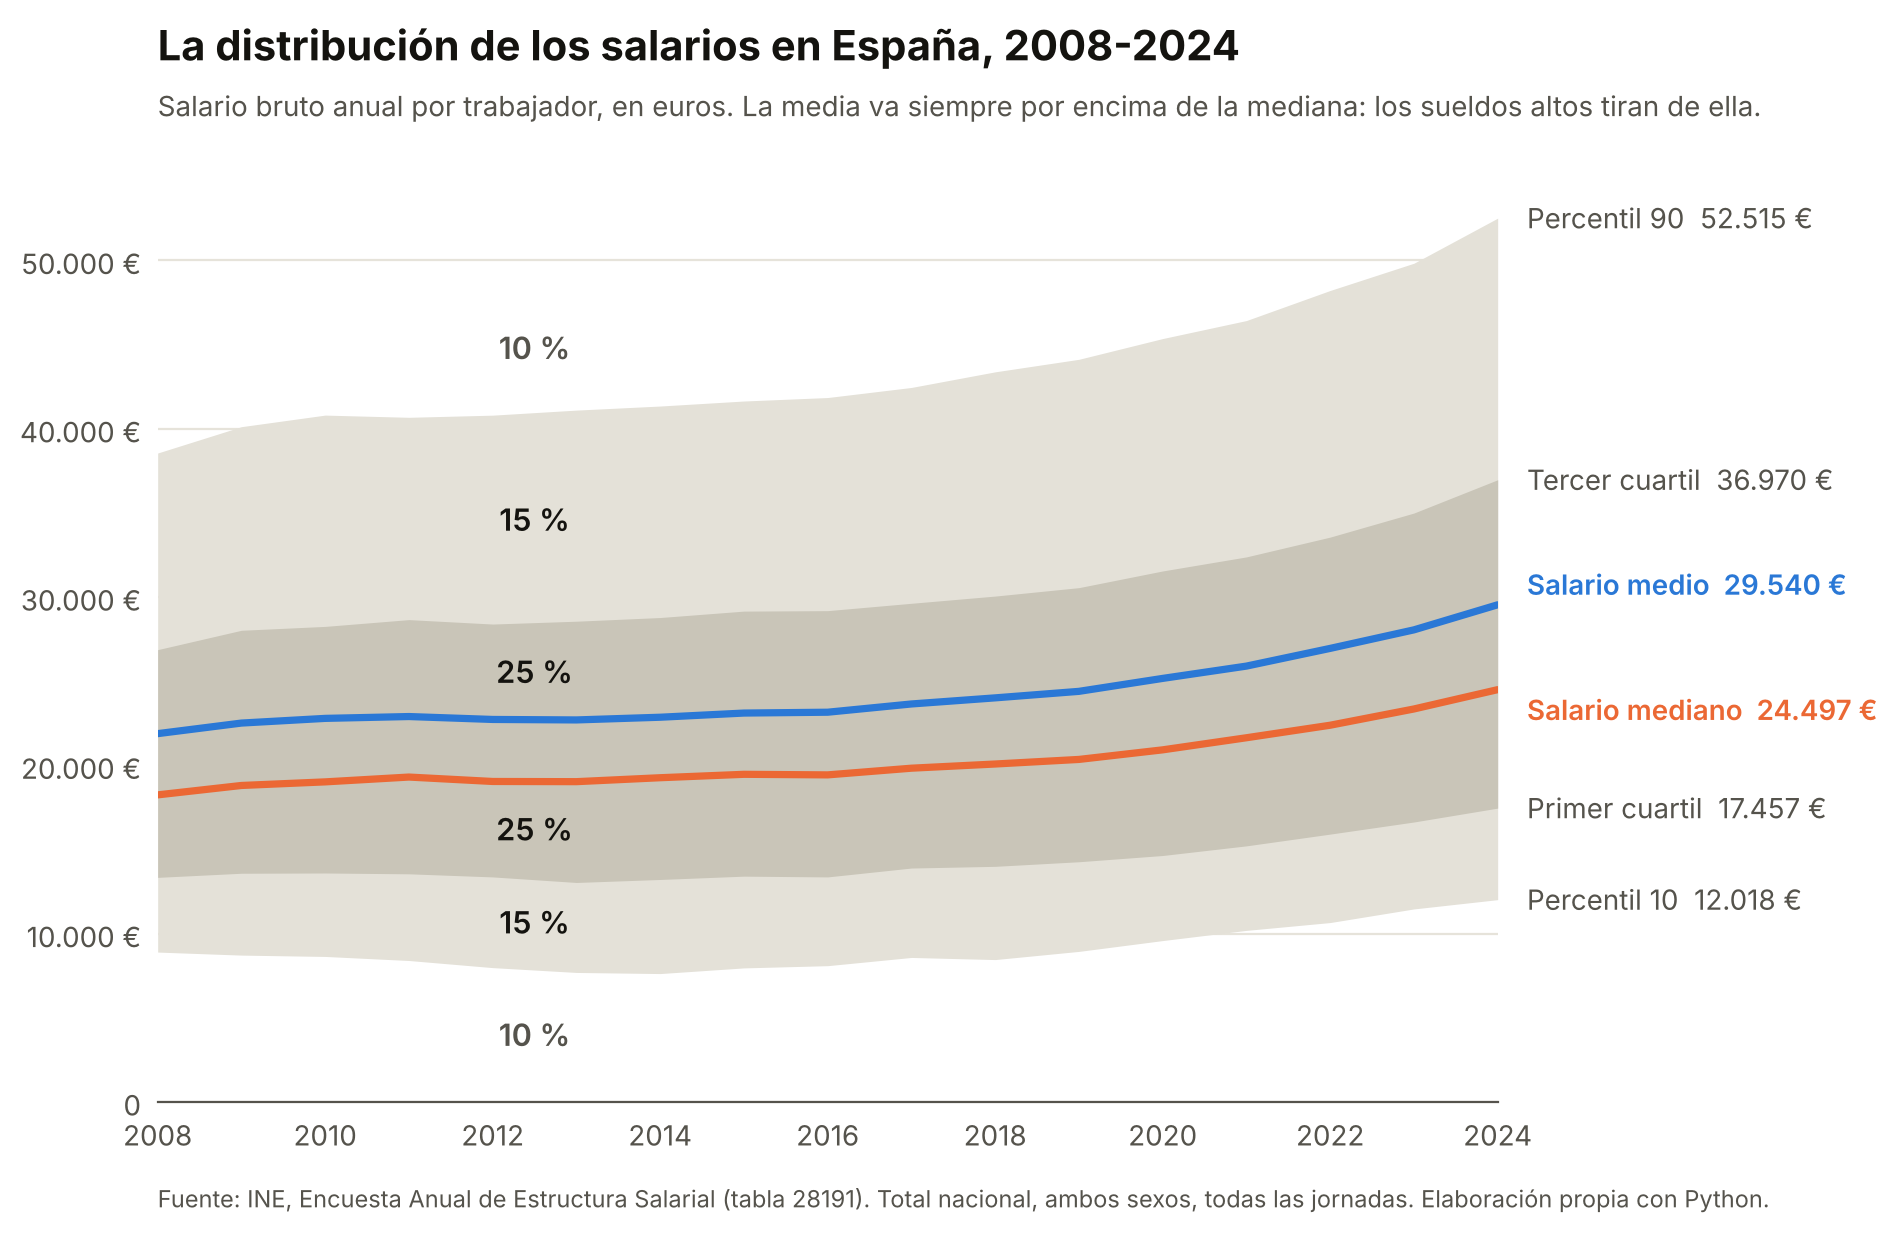

In [4]:
def euros(x):
    return f"{x:,.0f}".replace(",", ".")

fig, ax = plt.subplots(figsize=(10, 6.2), dpi=200)
fig.patch.set_facecolor(PAPEL); ax.set_facecolor(PAPEL)
x = nac.index

ax.fill_between(x, nac.p10, nac.p90, color=BANDA80, lw=0)
ax.fill_between(x, nac.q1, nac.q3, color=BANDA50, lw=0)
ax.plot(x, nac.mediana, color=NARANJA, lw=2.6, solid_capstyle="round")
ax.plot(x, nac.media, color=AZUL, lw=2.6, solid_capstyle="round")

# Etiquetas directas a la derecha (valor de 2024)
etiquetas = [("p90", "Percentil 90", TINTA2, 0), ("q3", "Tercer cuartil", TINTA2, 0),
             ("media", "Salario medio", AZUL, 1200), ("mediana", "Salario mediano", NARANJA, -1200),
             ("q1", "Primer cuartil", TINTA2, 0), ("p10", "Percentil 10", TINTA2, 0)]
for col, nombre, color, dy in etiquetas:
    v = nac[col].iloc[-1]
    peso = "semibold" if col in ("media", "mediana") else "normal"
    ax.annotate(f"{nombre}  {euros(v)} €", xy=(2024, v), xytext=(2024.35, v + dy),
                va="center", ha="left", fontsize=10, color=color, fontweight=peso,
                annotation_clip=False)

# Porcentaje de asalariados en cada franja, escrito en su centro (año 2012)
xr = 2012.5
fila = nac.loc[2012]
rotulos = [
    (fila.p10 / 2, "10 %", TINTA2),                    # por debajo del percentil 10
    ((fila.p10 + fila.q1) / 2, "15 %", TINTA),         # del percentil 10 al primer cuartil
    ((fila.q1 + fila.mediana) / 2, "25 %", TINTA),     # del primer cuartil a la mediana
    ((fila.media + fila.q3) / 2, "25 %", TINTA),       # de la mediana al tercer cuartil (sobre la media)
    ((fila.q3 + fila.p90) / 2, "15 %", TINTA),         # del tercer cuartil al percentil 90
    (fila.p90 + 4000, "10 %", TINTA2),                 # por encima del percentil 90
]
for y, texto, color in rotulos:
    ax.text(xr, y, texto, ha="center", va="center", fontsize=11, fontweight="semibold", color=color)

# Ejes
ax.set_xlim(2008, 2024); ax.set_ylim(0, 56000)
ax.set_xticks(range(2008, 2025, 2))
ax.yaxis.set_major_locator(mticker.MultipleLocator(10000))
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: euros(v) + " €" if v else "0"))
ax.grid(axis="y", color="#E6E3DA", lw=0.8); ax.set_axisbelow(True)
for lado in ("top", "right", "left"):
    ax.spines[lado].set_visible(False)
ax.spines["bottom"].set_color(TINTA2)
ax.tick_params(axis="both", length=0, labelsize=10, labelcolor=TINTA2, pad=6)

# Título, descripción y fuente
fig.subplots_adjust(left=0.09, right=0.76, top=0.87, bottom=0.11)
fig.text(0.09, 0.95, "La distribución de los salarios en España, 2008-2024",
         fontsize=15, fontweight="bold", color=TINTA)
fig.text(0.09, 0.905, "Salario bruto anual por trabajador, en euros. La media va siempre por encima "
         "de la mediana: los sueldos altos tiran de ella.", fontsize=10, color=TINTA2)
fig.text(0.09, 0.025, "Fuente: INE, Encuesta Anual de Estructura Salarial (tabla 28191). Total nacional, "
         "ambos sexos, todas las jornadas. Elaboración propia con Python.", fontsize=8.5, color=TINTA2)

plt.show()

## 5. Guardar la imagen

Se guarda como `figura2.png`. En Colab aparece en el panel de archivos (icono de carpeta, a la izquierda): descárgala y súbela a la carpeta `imagenes` del repositorio. La web y el PDF la leen desde ahí.

In [5]:
fig.savefig("figura2.png", dpi=200, facecolor=PAPEL)
print("Guardada: figura2.png")

Guardada: figura2.png
